<center><p float="center">
  
</p></center>

<center><font size=10>Restaurant Review Sentiment Analysis</center></font>


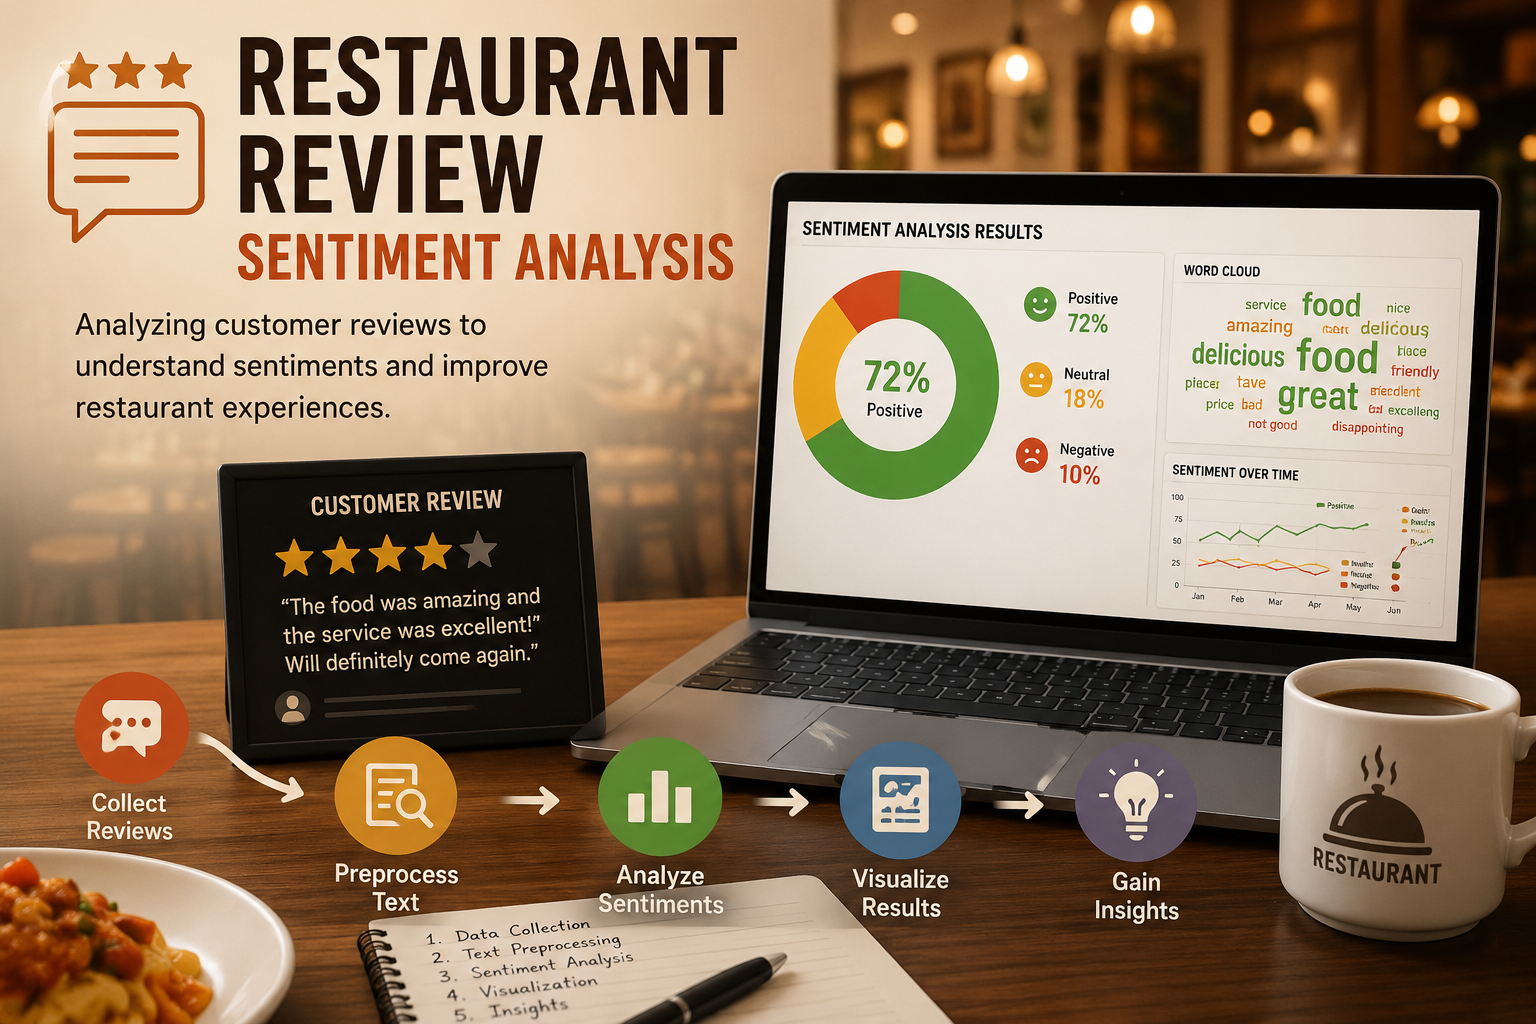

## Problem Statement

### Business Context

In the food industry, happy customers are very important for the success of each restaurant and the brand.
A big global food delivery company wants to understand and improve the customer experience in the restaurants on its platform.
The company knows that customer reviews are very useful.
They give ideas about service, food, and overall satisfaction.

### Objective

The objective is to build an **LLM-based sentiment analysis system** that finds useful insights from restaurant reviews using only **prompt engineering** (no RAG). The system will:

1. Find the **overall sentiment** (positive, negative, or neutral) of each review.
2. Find the **sentiment for each aspect**, such as food quality, service, and ambience.
3. Pick out the **liked and disliked points** in each aspect, so each restaurant gets detailed insights.

This approach helps restaurants understand customer feedback easily, improve their service, and make customers happier. All of this is done with **well-designed prompts**.

### Data Dictionary

The dataset comprises three columns:

1. **restaurant\_id** – Unique identifier for each restaurant.
2. **rating\_review** – Numerical or categorical rating provided by the customer.
3. **review\_full** – Full text of the customer’s review.


# Project Workflow:

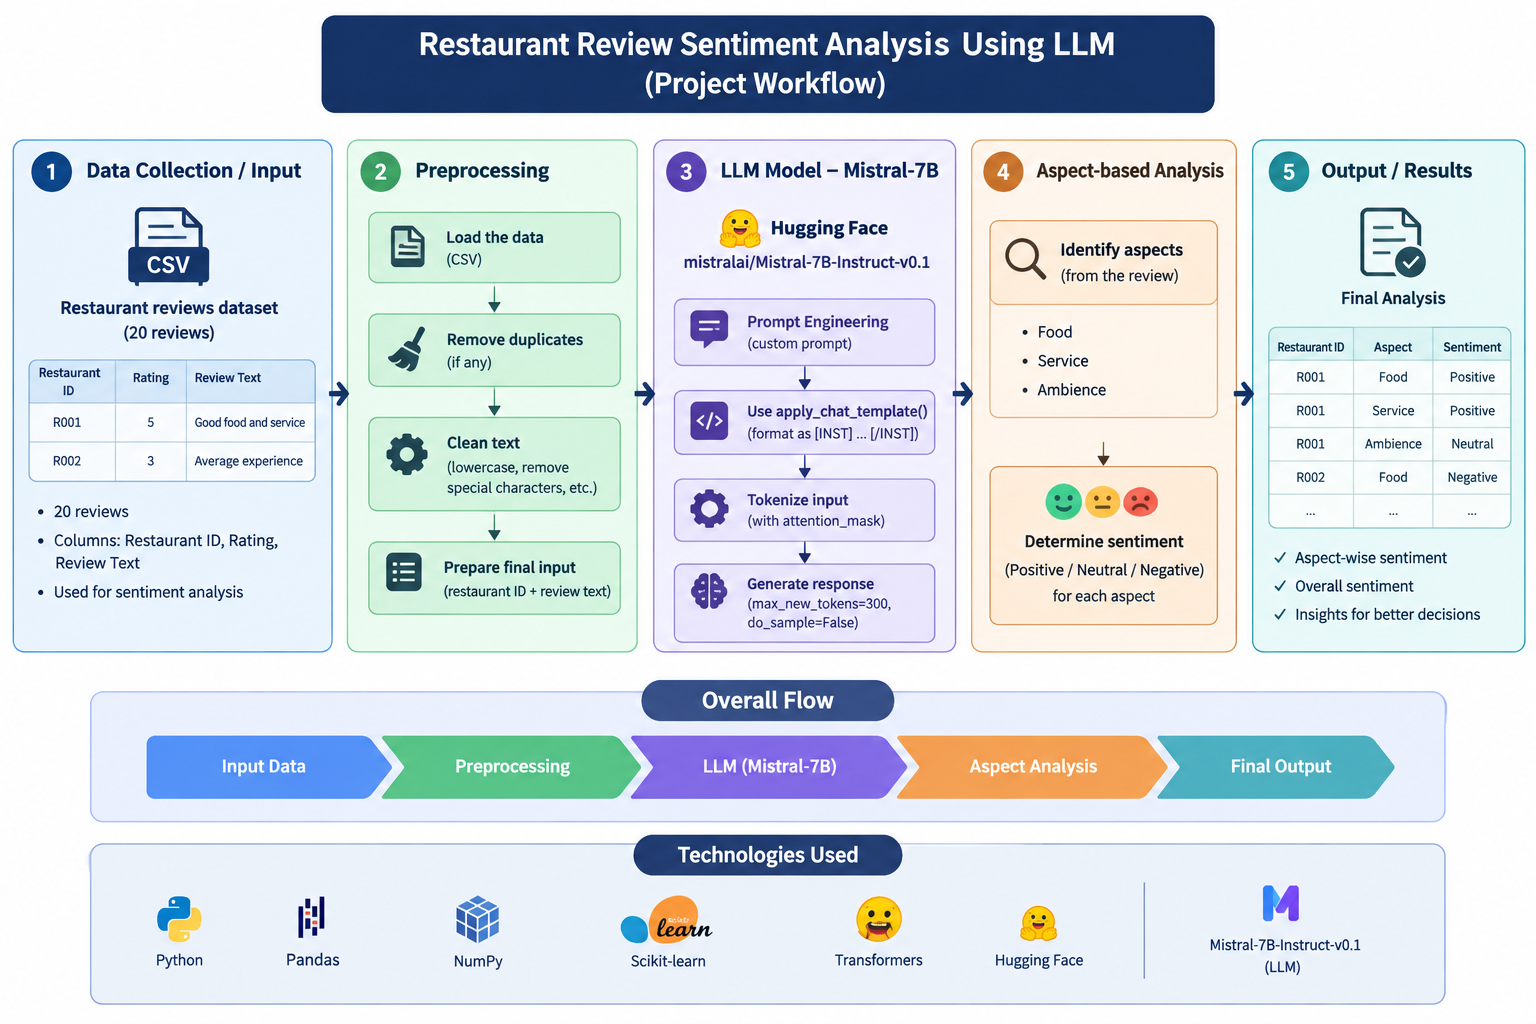

## Installing and Importing Necessary Libraries

In [ ]:
# Colab: use a GPU runtime first (Runtime > Change runtime type > T4 GPU)
# No version pins: old pins (bitsandbytes 0.46.1) break on the newer Colab CUDA/Python.
!pip install -q -U transformers accelerate bitsandbytes

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 21.3 MB/s eta 0:00:00


**Colab Setup Instructions:**
- Select a **GPU** runtime first: *Runtime > Change runtime type > T4 GPU*.
- After this install cell finishes, do **Runtime > Restart session**, then run the cells from the next one onwards. **Do not run this install cell again** after the restart.
- Dependency-conflict warnings during install can be ignored.

In [ ]:
import pandas as pd
import json
import os
import gc
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

assert torch.cuda.is_available(), "No GPU found. Use Runtime > Change runtime type > T4 GPU, then restart."
print("GPU:", torch.cuda.get_device_name(0))

GPU: Tesla T4


## Import the dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
data = pd.read_csv("/content/drive/MyDrive/Dataset/GenAIDataset/restaurant_reviews.csv")

## Data Overview

In [ ]:
# checking the first five rows of the data
data.head()

,restaurant_ID,rating_review,review_full
0,FLV202,5,"Totally in love with the Auro of the place, re..."
1,SAV303,5,Kailash colony is brimming with small cafes no...
2,YUM789,5,Excellent taste and awesome decorum. Must visi...
3,TST101,5,I have visited at jw lough/restourant. There w...
4,EAT456,5,Had a great experience in the restaurant food ...


In [ ]:
data.shape

(20, 3)

**Observations**

- Data has 20 rows and 3 columns

In [ ]:
# checking for missing values
data.isnull().sum()

,0
restaurant_ID,0
rating_review,0
review_full,0


**Observations**

- There are no missing values in the data

In [ ]:
# creating a copy of the data
df = data.copy()

# Model Loading

**Setup Details**

1. We're loading the entire model, which might take some time to initialize. To optimize this, we use 8-bit loading to reduce memory usage and speed up inference without significantly impacting performance.

2. Before loading the model, you must first agree to its terms and conditions on Hugging Face. To do this, search for the model on the Hugging Face website, review its license or usage restrictions, and click “Agree and Access” to enable programmatic access via code.


In [ ]:
# The Mistral-7B-Instruct-v0.1 model is public, so a token is optional.
# We try Colab Secrets, then config.json on Drive, and otherwise continue without one.
HF_TOKEN = None
try:
    from google.colab import userdata
    HF_TOKEN = userdata.get('HF_TOKEN')
except Exception:
    pass

if not HF_TOKEN:
    try:
        file_name = '/content/drive/MyDrive/Dataset/GenAIDataset/config.json'
        with open(file_name, 'r') as file:
            HF_TOKEN = json.load(file).get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

if HF_TOKEN:
    os.environ['HF_TOKEN'] = HF_TOKEN
print("HF token found:", bool(HF_TOKEN))

HF token found: True


In [ ]:
model_id = "mistralai/Mistral-7B-Instruct-v0.1"

tokenizer = AutoTokenizer.from_pretrained(model_id, token=HF_TOKEN)

def load_model():
    """Try 8-bit, then 4-bit, then plain fp16, so the notebook works on different Colab setups."""
    attempts = [
        ("8-bit", dict(quantization_config=BitsAndBytesConfig(load_in_8bit=True))),
        ("4-bit", dict(quantization_config=BitsAndBytesConfig(
            load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16, bnb_4bit_quant_type="nf4"))),
        ("fp16 (needs a GPU with ~16GB+, e.g. L4/A100)", dict(torch_dtype=torch.float16)),
    ]
    for name, kwargs in attempts:
        try:
            print(f"Loading Mistral-7B in {name} ...")
            m = AutoModelForCausalLM.from_pretrained(model_id, device_map="auto", token=HF_TOKEN, **kwargs)
            print(f"Loaded in {name}")
            return m
        except Exception as e:
            print(f"{name} failed: {type(e).__name__}: {str(e)[:200]}")
            gc.collect(); torch.cuda.empty_cache()
    raise RuntimeError("Could not load the model. Try a bigger GPU (L4/A100) or restart the session.")

model = load_model()

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.10k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.80M [00:00<?, ?B/s]

tokenizer.model: reconstructing file:   0%|          |  0.00B /  493kB            

tokenizer.model: downloading bytes:           |  0.00B            

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

Loaded in fp16 (needs a GPU with ~16GB+, e.g. L4/A100)


* `BitsAndBytesConfig(load_in_8bit=True)`: loads the model in 8-bit to save GPU memory (falls back to 4-bit, then fp16, if 8-bit is not supported in the current Colab environment).
* `device_map="auto"`: places model layers on the available GPU automatically.
* The model is public, so the Hugging Face token is optional.

Hugging Face model is now ready. Let’s test it on an example input.

In [ ]:
prompt = "[INST] What is the capital of France? [/INST]"
inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
outputs = model.generate(**inputs, max_new_tokens=30, do_sample=False, pad_token_id=tokenizer.eos_token_id)
print(tokenizer.decode(outputs[0][inputs["input_ids"].shape[-1]:], skip_special_tokens=True))

The capital of France is Paris.


Now that the model is returning results successfully.

Let’s define a function that takes a `prompt` and a `query` as inputs and returns the model’s output.  

This will make it easier to reuse the model across different inputs.

In [ ]:
def query_mistral(prompt, query):
    """
    Queries the Mistral model with an instruction (prompt) and a review (query).
    Returns the model's text response.
    """
    # Mistral-7B-Instruct-v0.1 has no system role, so the instruction and review go in one user message.
    messages = [{"role": "user", "content": f"{prompt}\n\nReview:\n{query}"}]

    encoded = tokenizer.apply_chat_template(
        messages, add_generation_prompt=True, return_tensors="pt", return_dict=True
    )
    input_ids = encoded["input_ids"].to(model.device)
    attention_mask = encoded["attention_mask"].to(model.device)

    with torch.no_grad():
        outputs = model.generate(
            input_ids=input_ids,
            attention_mask=attention_mask,
            max_new_tokens=300,
            do_sample=False,                       # deterministic output -> reproducible results
            pad_token_id=tokenizer.eos_token_id,
        )

    return tokenizer.decode(outputs[0][input_ids.shape[-1]:], skip_special_tokens=True).strip()

In `query_mistral`:

1. `apply_chat_template(...)`: formats the instruction + review into Mistral's `[INST] ... [/INST]` chat format and tokenizes it. `add_generation_prompt=True` tells the model to start answering.
2. `attention_mask`: tells the model which tokens are real input.
3. `max_new_tokens=300`: maximum length of the answer.
4. `do_sample=False`: greedy decoding, so the output is **deterministic** (same input gives same output). This makes the evaluation reproducible; `temperature` and `top_p` are not needed.
5. `torch.no_grad()`: no gradients needed for inference, which saves memory.

# Reviews Sentiment Analysis

## 1. Overall Sentiment Analysis

In [ ]:
# defining the instructions for the model
instruction_1 = """
    You are an AI analyzing restaurant reviews. Classify the sentiment of the provided review into the following categories:
    - Positive
    - Negative
    - Neutral

    And return in only JSON format. No extra text and analysis
    {"Sentiment":"Positive"}
"""

In [ ]:
import re

def parse_json(text):
    """Extract the first {...} block from the model output and parse it."""
    match = re.search(r"\{.*\}", text, re.DOTALL)
    return json.loads(match.group(0)) if match else None

def classify_sentiment(prompt, query, retries=2):
    """Query the model and retry if the output is not valid JSON."""
    for attempt in range(retries + 1):
        response_text = query_mistral(prompt, query)
        try:
            result = parse_json(response_text)
            if result is not None:
                return result
        except json.JSONDecodeError:
            pass
        print(f"Invalid JSON (attempt {attempt+1}), raw response: {response_text[:150]}")
    return None

In [ ]:
# One model call per review (the earlier version called the model twice per row)
results = [classify_sentiment(instruction_1, x) for x in df['review_full']]
df['Sentiment'] = [r.get('Sentiment') if r else None for r in results]

In [ ]:
df

,restaurant_ID,rating_review,review_full,Sentiment
0,FLV202,5,"Totally in love with the Auro of the place, re...",Positive
1,SAV303,5,Kailash colony is brimming with small cafes no...,Positive
2,YUM789,5,Excellent taste and awesome decorum. Must visi...,Positive
3,TST101,5,I have visited at jw lough/restourant. There w...,Positive
4,EAT456,5,Had a great experience in the restaurant food ...,Positive
5,RST-A1,5,We came across Perch by accident and had dinne...,Positive
6,DSH404,5,We went there on birthday special time. A nice...,Neutral
7,GRT505,3,Our visit to Green Bites on a busy Saturday ev...,Neutral
8,MMM606,3,"At Bella Cuisine, the cozy atmosphere and frie...",Neutral
9,FST707,3,Our dinner at Spice Haven provided a neutral e...,Neutral


In [ ]:
df['Sentiment'].value_counts()

,count
Sentiment,
Neutral,7
Negative,7
Positive,6


**Observation:** See the counts above. The numbers shown in the output are the source of truth (they are re-generated on every run).

## 2. Sentiment toward Different Aspects of the Experience

In [ ]:
# defining the instructions for the model
instruction_2 = """
    You are an AI analyzing restaurant reviews. Classify the following aspects in the review and classify the sentiment of each aspect as "Positive", "Negative", or "Neutral":
    1. "Food Quality"
    2. "Service"
    3. "Ambience"

    Output the overall sentiment and sentiment for each category in a JSON format with the following keys:
    {
        "Food Quality": "your_sentiment_prediction",
        "Service": "your_sentiment_prediction",
        "Ambience": "your_sentiment_prediction"
    }

    In case one of the three aspects is not mentioned in the review, set "Not Applicable" (including quotes) for the corresponding JSON key value.
    Only return the JSON, do not return any other information.
"""

In [ ]:
def classify_aspect_sentiment(prompt, query):
    """Returns the parsed JSON dict from the model (with retry), or None."""
    return classify_sentiment(prompt, query)

In [ ]:
# Apply the classification function to each row in the DataFrame
df['aspect_sentiment'] = df['review_full'].apply(lambda x: classify_aspect_sentiment(instruction_2, x))

# Normalize the JSON results into separate columns
aspect_sentiment_df = pd.json_normalize(df['aspect_sentiment'])

# Concatenate the original DataFrame with the new columns
df = pd.concat([df, aspect_sentiment_df], axis=1)

In [ ]:
df

,restaurant_ID,rating_review,review_full,Sentiment,aspect_sentiment,Food Quality,Service,Ambience
0,FLV202,5,"Totally in love with the Auro of the place, re...",Positive,"{'Food Quality': 'Positive', 'Service': 'Posit...",Positive,Positive,Positive
1,SAV303,5,Kailash colony is brimming with small cafes no...,Positive,"{'Food Quality': 'Positive', 'Service': 'Posit...",Positive,Positive,Positive
2,YUM789,5,Excellent taste and awesome decorum. Must visi...,Positive,"{'Food Quality': 'Positive', 'Service': 'Posit...",Positive,Positive,Positive
3,TST101,5,I have visited at jw lough/restourant. There w...,Positive,"{'Food Quality': 'Not Applicable', 'Service': ...",Not Applicable,Positive,Not Applicable
4,EAT456,5,Had a great experience in the restaurant food ...,Positive,"{'Food Quality': 'Positive', 'Service': 'Posit...",Positive,Positive,Neutral
5,RST-A1,5,We came across Perch by accident and had dinne...,Positive,"{'Food Quality': 'Positive', 'Service': 'Posit...",Positive,Positive,Positive
6,DSH404,5,We went there on birthday special time. A nice...,Neutral,"{'Food Quality': 'Negative', 'Service': 'Neutr...",Negative,Neutral,Positive
7,GRT505,3,Our visit to Green Bites on a busy Saturday ev...,Neutral,"{'Food Quality': 'Neutral', 'Service': 'Negati...",Neutral,Negative,Not Applicable
8,MMM606,3,"At Bella Cuisine, the cozy atmosphere and frie...",Neutral,"{'Food Quality': 'Negative', 'Service': 'Negat...",Negative,Negative,Positive
9,FST707,3,Our dinner at Spice Haven provided a neutral e...,Neutral,"{'Food Quality': 'Neutral', 'Service': 'Positi...",Neutral,Positive,Not Applicable


In [ ]:
df['Food Quality'].value_counts()

,count
Food Quality,
Positive,7
Negative,6
Neutral,5
Not Applicable,2


**Observation:** Compare the Positive/Negative/Neutral counts above to see how food quality is perceived.

In [ ]:
df['Service'].value_counts()

,count
Service,
Negative,10
Positive,9
Neutral,1


**Observation:** Compare the counts above to see how service is perceived.

In [ ]:
df['Ambience'].value_counts()

,count
Ambience,
Positive,8
Neutral,7
Not Applicable,4
Negative,1


**Observation:** Compare the counts above to see how ambience is perceived.

## 3. Identifying Liked/Disliked Features of the Different Aspects of the Experience

In [ ]:
# defining the instructions for the model
instruction_3 = """

You are an AI model assigned to analyze restaurant reviews. Your task is to extract the **specific features** that the customer **liked or disliked**, categorized under the following aspects of the dining experience:

* Food Quality
* Service
* Ambience

Return the result in the following strict JSON format:

{
  "Food Quality Features": ["specific liked/disliked features"],
  "Service Features": ["specific liked/disliked features"],
  "Ambience Features": ["specific liked/disliked features"]
}

**Instructions:**

* Only list **concrete features** (e.g., “taste”, “temperature”, “presentation”, “waiting time”, “staff behavior”, “lighting”, “music volume”) that are mentioned positively or negatively in the review.
* Do **not** include generic phrases like “liked feature” or “disliked feature”.
* If a particular aspect has no feature mentioned, return an empty list for that aspect.
* Output **only the JSON**, with keys exactly as specified. Do not add any explanations or comments.

"""

In [ ]:
def classify_features(prompt, query):
    """Returns the parsed JSON dict from the model (with retry), or None."""
    return classify_sentiment(prompt, query)

In [ ]:
# Apply the classification function to each row in the DataFrame
df['aspect_features'] = df['review_full'].apply(lambda x: classify_features(instruction_3, x))

# Normalize the JSON results into separate columns
aspect_features_df = pd.json_normalize(df['aspect_features'])

# Concatenate the original DataFrame with the new columns
df = pd.concat([df, aspect_features_df], axis=1)

In [ ]:
df

,restaurant_ID,rating_review,review_full,Sentiment,aspect_sentiment,Food Quality,Service,Ambience,aspect_features,Food Quality Features,Service Features,Ambience Features
0,FLV202,5,"Totally in love with the Auro of the place, re...",Positive,"{'Food Quality': 'Positive', 'Service': 'Posit...",Positive,Positive,Positive,{'Food Quality Features': ['pizza straight fro...,"[pizza straight from the oven, hummus and pita...",[],"[outdoor and indoor interior, marketplace ideo..."
1,SAV303,5,Kailash colony is brimming with small cafes no...,Positive,"{'Food Quality': 'Positive', 'Service': 'Posit...",Positive,Positive,Positive,"{'Food Quality Features': ['Margherita pizza',...","[Margherita pizza, Hummus, Pita, Fussili Alfre...",[],"[peaceful, plants]"
2,YUM789,5,Excellent taste and awesome decorum. Must visi...,Positive,"{'Food Quality': 'Positive', 'Service': 'Posit...",Positive,Positive,Positive,"{'Food Quality Features': ['taste'], 'Service ...",[taste],"[Subham Barnwal, great service]",[awesome decorum]
3,TST101,5,I have visited at jw lough/restourant. There w...,Positive,"{'Food Quality': 'Not Applicable', 'Service': ...",Not Applicable,Positive,Not Applicable,"{'Food Quality Features': [], 'Service Feature...",[],"[Ms. Laxmi, handling client needs, specialty, ...",[]
4,EAT456,5,Had a great experience in the restaurant food ...,Positive,"{'Food Quality': 'Positive', 'Service': 'Posit...",Positive,Positive,Neutral,"{'Food Quality Features': ['taste', 'presentat...","[taste, presentation]","[staff behavior, professionalism, helpfulness,...","[kids book, young guy]"
5,RST-A1,5,We came across Perch by accident and had dinne...,Positive,"{'Food Quality': 'Positive', 'Service': 'Posit...",Positive,Positive,Positive,"{'Food Quality Features': ['taste', 'presentat...","[taste, presentation, attentive service, range...",[attentive service],"[stylish decor, lively music, tasteful music]"
6,DSH404,5,We went there on birthday special time. A nice...,Neutral,"{'Food Quality': 'Negative', 'Service': 'Neutr...",Negative,Neutral,Positive,{'Food Quality Features': ['Pulled Duck Salad'...,"[Pulled Duck Salad, Mulled Wine, Holiday Coffee]",[],"[Interior, Lighting, Cozy feel]"
7,GRT505,3,Our visit to Green Bites on a busy Saturday ev...,Neutral,"{'Food Quality': 'Neutral', 'Service': 'Negati...",Neutral,Negative,Not Applicable,"{'Food Quality Features': ['tasty', 'average']...","[tasty, average]","[slow, attentive staff]",[]
8,MMM606,3,"At Bella Cuisine, the cozy atmosphere and frie...",Neutral,"{'Food Quality': 'Negative', 'Service': 'Negat...",Negative,Negative,Positive,"{'Food Quality Features': ['flavorful', 'disti...","[flavorful, distinctive taste]",[inconsistent],"[cozy atmosphere, friendly staff]"
9,FST707,3,Our dinner at Spice Haven provided a neutral e...,Neutral,"{'Food Quality': 'Neutral', 'Service': 'Positi...",Neutral,Positive,Not Applicable,"{'Food Quality Features': ['menu options', 'pr...","[menu options, preparation]","[efficiency, attentiveness]",[]


## Evaluation of Overall Sentiment

The dataset already has a star rating (`rating_review`). We use it as a proxy ground truth: **5 = Positive, 3 = Neutral, 1 = Negative**, and measure how often the LLM agrees.

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

rating_map = {5: 'Positive', 3: 'Neutral', 1: 'Negative'}
df['expected'] = df['rating_review'].map(rating_map)

def normalise(x):
    return x.strip().capitalize() if isinstance(x, str) else None

df['Sentiment'] = df['Sentiment'].apply(normalise)
labels = ['Positive', 'Neutral', 'Negative']

acc_v1 = accuracy_score(df['expected'], df['Sentiment'])
f1_v1 = f1_score(df['expected'], df['Sentiment'], average='macro', labels=labels)
print(f"Baseline prompt  ->  Accuracy: {acc_v1:.2f} | Macro-F1: {f1_v1:.2f}")
print(classification_report(df['expected'], df['Sentiment'], labels=labels, zero_division=0))
print(pd.DataFrame(confusion_matrix(df['expected'], df['Sentiment'], labels=labels),
                   index=[f'true_{l}' for l in labels], columns=[f'pred_{l}' for l in labels]))

Baseline prompt  ->  Accuracy: 0.95 | Macro-F1: 0.95
              precision    recall  f1-score   support

    Positive       1.00      0.86      0.92         7
     Neutral       0.86      1.00      0.92         6
    Negative       1.00      1.00      1.00         7

    accuracy                           0.95        20
   macro avg       0.95      0.95      0.95        20
weighted avg       0.96      0.95      0.95        20

               pred_Positive  pred_Neutral  pred_Negative
true_Positive              6             1              0
true_Neutral               0             6              0
true_Negative              0             0              7


### Prompt Improvement: Few-shot Examples
We add short labelled examples to the prompt so the model understands what *Neutral* (mixed or lukewarm) looks like.

In [ ]:
instruction_1_fewshot = """
You are an AI analyzing restaurant reviews. Classify the overall sentiment of the review as Positive, Negative or Neutral.
- Positive: clearly satisfied, recommends the place.
- Negative: clearly dissatisfied, complains about problems.
- Neutral: mixed opinion, or both good and bad points, or average experience.

Return ONLY JSON, no extra text. Examples:

Review: "Amazing food and super friendly staff, will definitely come again!"
{"Sentiment":"Positive"}

Review: "Food was okay but the service was slow. Nothing special."
{"Sentiment":"Neutral"}

Review: "Cold food, rude waiter and we waited an hour. Never coming back."
{"Sentiment":"Negative"}
"""

results_v2 = [classify_sentiment(instruction_1_fewshot, x) for x in df['review_full']]
df['Sentiment_v2'] = [normalise(r.get('Sentiment')) if r else None for r in results_v2]

acc_v2 = accuracy_score(df['expected'], df['Sentiment_v2'])
f1_v2 = f1_score(df['expected'], df['Sentiment_v2'], average='macro', labels=labels)

pd.DataFrame({
    'Prompt': ['Baseline (zero-shot)', 'Few-shot + definitions'],
    'Accuracy': [acc_v1, acc_v2],
    'Macro_F1': [f1_v1, f1_v2],
})

,Prompt,Accuracy,Macro_F1
0,Baseline (zero-shot),0.95,0.948718
1,Few-shot + definitions,0.95,0.948718


### Error Analysis
Reviews where the model disagrees with the rating. Check whether the model is wrong, or the rating itself does not match the text.

In [ ]:
best_col = 'Sentiment_v2' if acc_v2 >= acc_v1 else 'Sentiment'
errors = df[df[best_col] != df['expected']][['restaurant_ID', 'rating_review', 'expected', best_col, 'review_full']]
pd.set_option('display.max_colwidth', 250)
errors

,restaurant_ID,rating_review,expected,Sentiment_v2,review_full
6,DSH404,5,Positive,Neutral,We went there on birthday special time. A nice place for evening drinks and food. Spend your time with friends in this place over conversation. The interior is friendly and not intimidating like any other pubs.The place has very soft lighting and...


**Note:** The dataset has only 20 reviews, so the accuracy figure is indicative, not statistically strong. The model used is `Mistral-7B-Instruct-v0.1` (an older 7B model loaded in 8-bit); newer models would likely do better.

## 4. Sharing a Response

In [ ]:
# defining the instructions for the model
instruction_4 = """
You are an AI analyzing restaurant reviews. Your task is to generate a **polite and empathetic response** directly based on the sentiment of the review.

Follow this structure:

* Start with a thank you for their feedback.
* Then:

  1. If the review is positive, say you’re glad they enjoyed the experience and that it would be great to have them again.
  2. If the review is neutral, thank them and ask what the restaurant could have done better.
  3. If the review is negative, apologize for the inconvenience and mention that the team will look into the concerns raised.

Constraints:

* Do not start with “Dear Customer” or any greeting.
* Only output the final response. No sentiment label, explanation, or extra text.
"""

In [ ]:
def generate_customer_response(prompt, query):
    """
    Generates a customer response based on the review using the Mistral model.

    Args:
        prompt (str): The prompt for the model (instruction_4).
        query (str): The review text.

    Returns:
        str: The generated customer response.
    """
    response_text = query_mistral(prompt, query)
    return response_text

In [ ]:
# Apply the classification function to each row in the DataFrame
df['customer_response'] = df['review_full'].apply(lambda x: generate_customer_response(instruction_4, x))

In [ ]:
df

,restaurant_ID,rating_review,review_full,Sentiment,aspect_sentiment,Food Quality,Service,Ambience,aspect_features,Food Quality Features,Service Features,Ambience Features,expected,Sentiment_v2,customer_response
0,FLV202,5,"Totally in love with the Auro of the place, really beautiful and quite fancy at the same time. The ambience is very pure and gives a sense of positivity throughout. Outdoor and indoor interior are quite quaint and cute. Love the open kitchen idea...",Positive,"{'Food Quality': 'Positive', 'Service': 'Positive', 'Ambience': 'Positive'}",Positive,Positive,Positive,"{'Food Quality Features': ['pizza straight from the oven', 'hummus and pita bread'], 'Service Features': [], 'Ambience Features': ['outdoor and indoor interior', 'marketplace ideology', 'pure and positive ambience']}","[pizza straight from the oven, hummus and pita bread]",[],"[outdoor and indoor interior, marketplace ideology, pure and positive ambience]",Positive,Positive,Thank you for your feedback! We're thrilled to hear that you enjoyed your experience at Auro and that the ambience and food were particularly impressive. We appreciate your kind words about our use of disposable cutlery and other safety measures ...
1,SAV303,5,"Kailash colony is brimming with small cafes now. I happened to visit this beauty for lunch and was amazed with the 1st impression it made. We started with Falafel & Pita and Margherita Pizza. Safe to say, Margherita pizza was the best choice of ...",Positive,"{'Food Quality': 'Positive', 'Service': 'Positive', 'Ambience': 'Positive'}",Positive,Positive,Positive,"{'Food Quality Features': ['Margherita pizza', 'Hummus', 'Pita', 'Fussili Alfredo', 'Frozen Yoghurt'], 'Service Features': [], 'Ambience Features': ['peaceful', 'plants']}","[Margherita pizza, Hummus, Pita, Fussili Alfredo, Frozen Yoghurt]",[],"[peaceful, plants]",Positive,Positive,"Thank you for your feedback. We're glad you enjoyed your experience at Kailash colony and appreciate your kind words about the Margherita pizza. We're sorry to hear that the Fussili Alfredo didn't meet your expectations, and we'll make sure to im..."
2,YUM789,5,Excellent taste and awesome decorum. Must visit. Subham Barnwal had given us a great service. One of the best experience.,Positive,"{'Food Quality': 'Positive', 'Service': 'Positive', 'Ambience': 'Positive'}",Positive,Positive,Positive,"{'Food Quality Features': ['taste'], 'Service Features': ['Subham Barnwal', 'great service'], 'Ambience Features': ['awesome decorum']}",[taste],"[Subham Barnwal, great service]",[awesome decorum],Positive,Positive,"Thank you for your feedback. We're glad to hear that you enjoyed the taste and decorum of our restaurant. It would be great to have you back again. Subham Barnwal provided excellent service, making your experience one of the best. We appreciate y..."
3,TST101,5,"I have visited at jw lough/restourant. There were a first class service at lough, specially Ms.laxmi who were superbed for handling the client need, me and my family lots enjoyed her specialty in the manner, and Laxmi is a very very good in the ...",Positive,"{'Food Quality': 'Not Applicable', 'Service': 'Positive', 'Ambience': 'Not Applicable'}",Not Applicable,Positive,Not Applicable,"{'Food Quality Features': [], 'Service Features': ['Ms. Laxmi', 'handling client needs', 'specialty', 'manner', 'client service', 'Laxmi is a very very good in client service', 'Ms. Laxmi', 'wonderful girl in service'], 'Ambience Features': []}",[],"[Ms. Laxmi, handling client needs, specialty, manner, client service, Laxmi is a very very good in client service, Ms. Laxmi, wonderful girl in service]",[],Positive,Positive,"Thank you for your feedback at JW Marriott Hotel in Atrocity, Delhi. We're glad to hear that you enjoyed your experience and specifically appreciated Ms. Laxmi's service. We're thrilled to hear that she was able to meet your needs and that you fo..."
4,EAT456,5,"Had a great experience in the restaurant food was fabulous, staff w

## Conclusions

We used a Large Language Model (LLM) in a **multi-stage prompt-engineering pipeline** to extract insights from restaurant reviews:

1. **Overall sentiment** of each review (Positive / Neutral / Negative).
2. **Aspect-level sentiment** for Food Quality, Service and Ambience.
3. **Liked / disliked features** within each aspect.
4. **Auto-generated customer reply** based on the review's sentiment.

**Evaluation:** Since the data includes star ratings, we mapped 5 -> Positive, 3 -> Neutral, 1 -> Negative and measured accuracy and macro-F1 of the LLM. We then improved the prompt with sentiment definitions and few-shot examples and compared both versions (see the comparison table above).

**Reliability improvements:** deterministic decoding (`do_sample=False`), JSON extraction with retry, and a single model call per review.

**Limitations:** only 20 reviews, an older 7B model, and star ratings used as a proxy for true labels. Next steps: a larger manually labelled set, a stronger model, and a Gradio demo UI.

<center><p float="center">
  
</p></center>

<center><font size=10>Thank You</center></font>